# Crop Disease Classification Using CNNs

## Problem Statement

Crop diseases can significantly reduce agricultural productivity and crop yields if they are not identified early. This project aims to develop a Convolutional Neural Network (CNN) that classifies potato and tomato leaf images into 13 categories, identifying whether a leaf is healthy or affected by a specific disease.

Early disease identification can help farmers and agricultural professionals recognize potential crop health problems sooner, allowing them to take appropriate action and reduce potential crop losses.

In [5]:
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [21]:
import numpy as np
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from tensorflow.keras import layers, models

!pip install -q importlib_resources

IMG = 64
RANDOM_STATE = 42
tf.keras.utils.set_random_seed(RANDOM_STATE)

## Dataset

The PlantVillage dataset is obtained through TensorFlow Datasets (TFDS). It contains 54,303 images across 38 categories representing different crops and their corresponding diseases.

For this project, I selected 13 categories belonging to potato and tomato plants. This reduces the classification problem to a more focused set of diseases while keeping the dataset manageable for training.

In [7]:
ds, info = tfds.load(
    "plant_village",
    split="train",
    with_info=True,
    as_supervised=True,
    data_dir="/content/drive/MyDrive/tensorflow_datasets",
)

class_names = info.features["label"].names
print(class_names)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy', 'Corn___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Spot', 'Tomato___Tomato_mosaic_virus', 'Tomato___

(256, 256, 3) <dtype: 'uint8'>
tf.Tensor(35, shape=(), dtype=int64) <dtype: 'int64'>


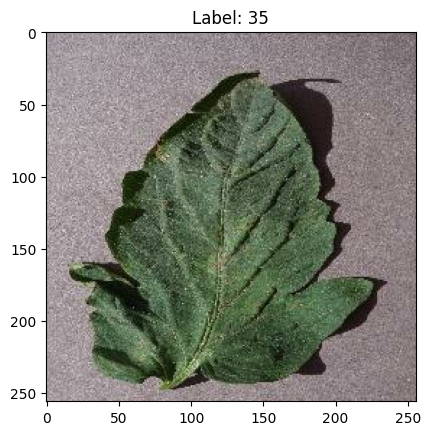

In [8]:
for img, label in ds.take(1):
    print(img.shape, img.dtype)
    print(label, label.dtype)
    plt.imshow(img.numpy())
    plt.title(f"Label: {label.numpy()}")
    plt.show()

In [9]:
def preprocess(image, label):
    image = tf.image.resize(image, (IMG, IMG))
    image = tf.cast(image, tf.uint8)
    return image, label

## Selected Classes

Potatoes and tomatoes are two widely grown crops, and diseases such as Early Blight and Late Blight can cause significant crop losses.

Narrowing the dataset from 38 to 13 classes keeps training manageable while allowing the model to focus on distinguishing between healthy leaves and different diseases affecting these two crops.

In [10]:
selected_classes = [
    "Potato___Early_blight",
    "Potato___healthy",
    "Potato___Late_blight",
    "Tomato___Bacterial_spot",
    "Tomato___Early_blight",
    "Tomato___healthy",
    "Tomato___Late_blight",
    "Tomato___Leaf_Mold",
    "Tomato___Septoria_leaf_spot",
    "Tomato___Spider_mites Two-spotted_spider_mite",
    "Tomato___Target_Spot",
    "Tomato___Tomato_mosaic_virus",
    "Tomato___Tomato_Yellow_Leaf_Curl_Virus",
]
selected_ids = [class_names.index(name) for name in selected_classes]

filtered_ds = ds.map(preprocess).filter(
    lambda image, label: tf.reduce_any(label == selected_ids)
)

## Data Preprocessing

All selected images are resized to 64 × 64 pixels to provide a consistent input size for the CNN.

The images are also filtered to include only the 13 selected categories. Their original labels are remapped to consecutive integers starting from zero so they can be used by the classification model.

In [11]:
images = []
labels = []

for img, lab in filtered_ds.as_numpy_iterator():
    images.append(img)
    labels.append(lab)

X = np.stack(images)
y_old = np.array(labels)

# Remapping labels to start from 0
label_map = {orig_id: new_id for new_id, orig_id in enumerate(selected_ids)}

y = np.array([label_map[label] for label in y_old])

## Class Balancing

To prevent certain categories from dominating the training process, I limited each class to a maximum of 1,000 images.

This creates a more balanced dataset, allowing the model to learn from each category without being heavily influenced by classes with more available images.

In [12]:
CAP = 1000  # Image limit for a class
rng = np.random.default_rng(RANDOM_STATE)

selected = []
for class_id in range(len(selected_classes)):
    class_indices = np.where(y == class_id)[0]

    if len(class_indices) > CAP:
        chosen = rng.choice(class_indices, size=CAP, replace=False)
    else:
        chosen = class_indices

    selected.append(chosen)

selected = np.concatenate(selected)
rng.shuffle(selected)

X_capped = X[selected]
y_capped = y[selected]

counts = np.bincount(y_capped)
for i, name in enumerate(selected_classes):
    print(i, name, counts[i])

0 Potato___Early_blight 1000
1 Potato___healthy 152
2 Potato___Late_blight 1000
3 Tomato___Bacterial_spot 1000
4 Tomato___Early_blight 1000
5 Tomato___healthy 1000
6 Tomato___Late_blight 1000
7 Tomato___Leaf_Mold 952
8 Tomato___Septoria_leaf_spot 1000
9 Tomato___Spider_mites Two-spotted_spider_mite 1000
10 Tomato___Target_Spot 1000
11 Tomato___Tomato_mosaic_virus 373
12 Tomato___Tomato_Yellow_Leaf_Curl_Virus 1000


## Training, Validation, and Testing Sets

The dataset is divided into three subsets:

- Training: 64% of the data
- Validation: 16% of the data
- Testing: 20% of the data

Stratified sampling is used to maintain the proportion of each class across the three subsets, while a fixed random seed ensures reproducibility.

In [13]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X_capped, y_capped, test_size=0.2, random_state=RANDOM_STATE, stratify=y_capped
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train_val,
    y_train_val,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train_val,
)

## CNN Model Architecture

The model consists of three convolutional layers, each followed by max pooling, to extract important visual features from the leaf images.

The extracted features are flattened and passed through a dense layer before the final softmax layer predicts the probability of each of the 13 categories.

In [14]:
model = models.Sequential(
    [
        layers.Input(shape=(IMG, IMG, 3)),
        layers.Conv2D(16, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(len(selected_classes), activation="softmax"),
    ]
)

## Model Training

The model is compiled using the Adam optimizer and sparse categorical crossentropy loss function. Accuracy is used as the primary training metric. The model is trained for 20 epochs with a batch size of 32.

Validation data is used to monitor model performance on images that are not included in training.

In [15]:
model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)

model.summary()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=32,
    verbose=0,
)

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 13)             │           845 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 88,973 (347.55 KB)

 Trainable params: 88,973 (347.55 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
230/230 - 19s - 84ms/step - accuracy: 0.2759 - loss: 2.7243 - val_accuracy: 0.4300 - val_loss: 1.7400
Epoch 2/20
230/230 - 18s - 79ms/step - accuracy: 0.5545 - loss: 1.3233 - val_accuracy: 0.6184 - val_loss: 1.1268
Epoch 3/20
230/230 - 16s - 71ms/step - accuracy: 0.6913 - loss: 0.9235 - val_accuracy: 0.6663 - val_loss: 1.0195
Epoch 4/20
230/230 - 17s - 76ms/step - accuracy: 0.7529 - loss: 0.7222 - val_accuracy: 0.7153 - val_loss: 0.8734
Epoch 5/20
230/230 - 17s - 76ms/step - accuracy: 0.7966 - loss: 0.5912 - val_accuracy: 0.7213 - val_loss: 0.9288
Epoch 6/20
230/230 - 17s - 72ms/step - accuracy: 0.8133 - loss: 0.5369 - val_accuracy: 0.7082 - val_loss: 0.9321
Epoch 7/20
230/230 - 17s - 72ms/step - accuracy: 0.8320 - loss: 0.4743 - val_accuracy: 0.7572 - val_loss: 0.8188
Epoch 8/20
230/230 - 18s - 79ms/step - accuracy: 0.8508 - loss: 0.4266 - val_accuracy: 0.6805 - val_loss: 1.2234
Epoch 9/20
230/230 - 16s - 71ms/step - accuracy: 0.8781 - loss: 0.3636 - val_accuracy: 0.7632 - 

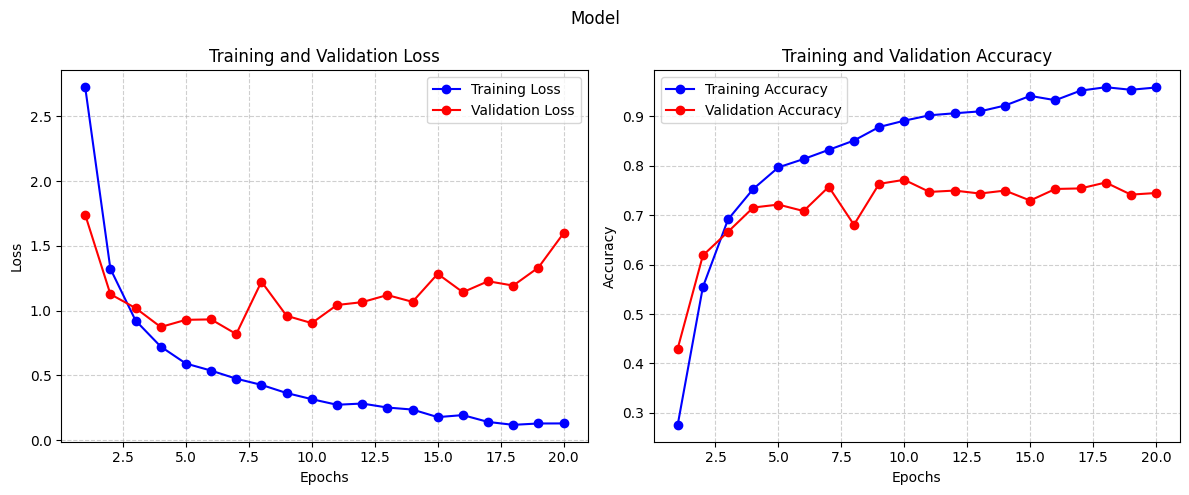

In [16]:
def plot_training_history(history, name="Model"):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']

    epochs = range(1, len(acc) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

    ax1.plot(epochs, loss, 'bo-', label='Training Loss')
    ax1.plot(epochs, val_loss, 'ro-', label='Validation Loss')
    ax1.set_title('Training and Validation Loss')
    ax1.set_xlabel('Epochs')
    ax1.set_ylabel('Loss')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.6)

    ax2.plot(epochs, acc, 'bo-', label='Training Accuracy')
    ax2.plot(epochs, val_acc, 'ro-', label='Validation Accuracy')
    ax2.set_title('Training and Validation Accuracy')
    ax2.set_xlabel('Epochs')
    ax2.set_ylabel('Accuracy')
    ax2.legend()
    ax2.grid(True, linestyle='--', alpha=0.6)

    plt.suptitle(name)
    plt.tight_layout()
    plt.show()

plot_training_history(history)


In [55]:
baseline_probs = model.predict(X_val, verbose=0)
baseline_pred = np.argmax(baseline_probs, axis=1)

baseline_acc = accuracy_score(y_val, baseline_pred)
print(baseline_acc)

clean_labels = [
    name.replace("___", " ").replace("_", " ").replace("Tomato Tomato", "Tomato").replace("Tomato Spider mites Two-spotted spider mite", "Tomato spider mite")
    for name in selected_classes
]


0.7446924333151878


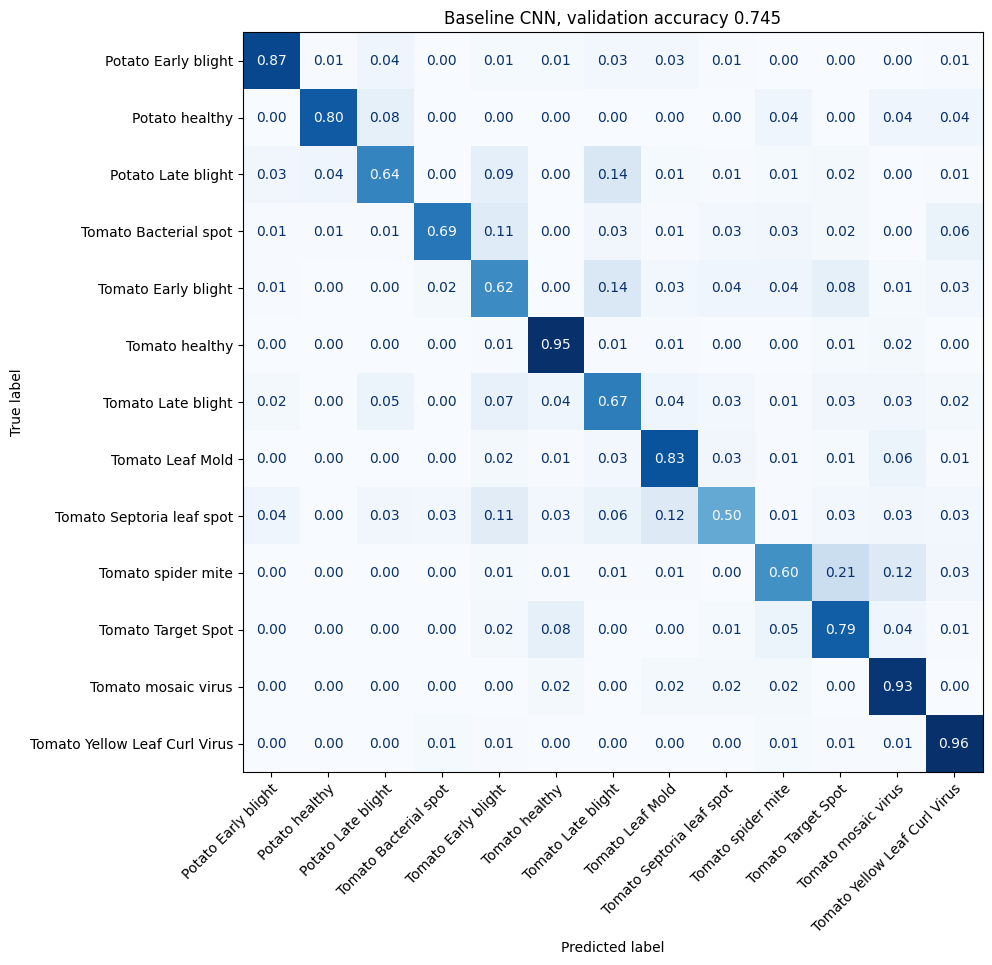

In [54]:

def plot_confusion(y_true, y_pred, title):
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, normalize='true')
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clean_labels)

    fig, ax = plt.subplots(figsize=(10, 10))
    disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False, values_format='.2f')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    ax.set_title(f"{title}, validation accuracy {acc:.3f}")
    plt.tight_layout()
    plt.show()
    return acc

baseline_acc = plot_confusion(y_val, baseline_pred, "Baseline CNN")